# Claudius — data

The ImplicitBenchmark Claudius data set (G. Caumon; `data/_README.md`): four horizons,
A (youngest) to D, picked on the Claudius 3-D seismic survey over Upper Triassic carbonate
build-ups in the Carnarvon Basin, offshore Western Australia, with 25 bedding readings and a
fault that affects horizon D. Z is two-way time times −3, positive up; North is +x, East +y.

This notebook only prepares the data, for the LDI fit (`06b_claudius_ldi`) and Surfe
(`06c_claudius_surfe`):

- the frame: UTM shifted to the centre of the benchmark's suggested box, so the Fourier phases
  stay well conditioned in single precision;
- the bedding poles turned to point up, so they are younging normals;
- the evaluation grid: the box and resolution the benchmark suggests (100 × 100 × 90 m,
  38 × 55 × 30 nodes);
- every contact, and the benchmark's random `Cutoff` stored with it. A fit does not use that
  number: it keeps a fraction of each horizon spaced evenly through the cloud, so the kept
  points do not clump, and is scored on the rest (`claudius_inputs.load_processed(cutoff)`).

The fault is saved for the figures but no fit uses it. Writes `data/processed/`.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle
import figstyle
figstyle.apply()

RAW_DIR = Path("data")
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Box and frame

The benchmark's suggested box (UTM, metres) and resolution. Coordinates are shifted to the
box centre.

In [2]:
BOX_UTM = np.array([[548800.0, 7816600.0, -11010.0], [552500.0, 7822000.0, -8400.0]])
STEP = np.array([50.0, 50.0, 50.0])      # m;

origin = BOX_UTM.mean(0)
box = BOX_UTM - origin
x, y, z = (np.linspace(lo, hi, int(round((hi - lo) / s)) + 1) for lo, hi, s in zip(*box, STEP))
print(f"origin (UTM) {origin}, box {np.ptp(box, axis=0)} m, grid {len(x)} x {len(y)} x {len(z)}")

origin (UTM) [ 550650. 7819300.   -9705.], box [3700. 5400. 2610.] m, grid 75 x 109 x 53


## Contacts, bedding and fault

Each horizon's points with their `Cutoff`. The bedding readings in `Dips.csv` are poles that
point down; flipped, they are younging normals (way up).

In [3]:
HORIZONS = ("A", "B", "C", "D")            # youngest first

points, cutoffs = [], []
for name in HORIZONS:
    df = pd.read_csv(RAW_DIR / f"{name}Points.csv", delimiter=";")
    points.append(df[["X", "Y", "Z"]].to_numpy(float) - origin)
    cutoffs.append(df["Cutoff"].to_numpy(float))

dips = pd.read_csv(RAW_DIR / "Dips.csv", delimiter=";")
gp = dips[["X", "Y", "Z"]].to_numpy(float) - origin
gv = dips[["OrientX", "OrientY", "OrientZ"]].to_numpy(float)
gv = -gv / np.linalg.norm(gv, axis=1, keepdims=True)
fault = pd.read_csv(RAW_DIR / "Fault.csv", delimiter=";")[["X", "Y", "Z"]].to_numpy(float) - origin

for name, p in zip(HORIZONS, points):
    inside = np.all((p >= box[0]) & (p <= box[1]), axis=1).mean()
    print(f"{name}: {len(p)} points, z {p[:, 2].min():.0f} to {p[:, 2].max():.0f} m, {inside:.0%} inside the box")
print(f"{len(gp)} bedding readings, all younging up: {bool(np.all(gv[:, 2] > 0))}; fault {len(fault)} points")
# stratigraphic order: the mean elevation should fall from A to D
print("mean z:", [f"{p[:, 2].mean():.0f}" for p in points])

A: 5000 points, z 726 to 1023 m, 100% inside the box
B: 5000 points, z 478 to 831 m, 100% inside the box
C: 5000 points, z -67 to 335 m, 100% inside the box
D: 4954 points, z -933 to 153 m, 100% inside the box
25 bedding readings, all younging up: True; fault 93 points
mean z: ['857', '637', '72', '-528']


## Clamp the box to the seismics

The benchmark's suggested box reaches past the picks: they stop 77 to 150 m inside it. With `CLAMP_TO_PICKS` the
box (and the evaluation grid, at the same `STEP`) ends where the picks end in x and y, so the fits are scored and
meshed only where there are seismics. The vertical range is left as it is. The coordinate origin does not move, so
positions are unchanged; only `box`, `x` and `y` shrink.

In [4]:
CLAMP_TO_PICKS = True      # the box ends where the seismic picks end in x and y (False: the benchmark's suggested box)

if CLAMP_TO_PICKS:
    picks_xy = np.vstack(points)[:, :2]
    box = box.copy()
    box[0, :2] = np.maximum(box[0, :2], picks_xy.min(axis=0))
    box[1, :2] = np.minimum(box[1, :2], picks_xy.max(axis=0))
    x, y, z = (np.linspace(lo, hi, int(round((hi - lo) / s)) + 1) for lo, hi, s in zip(*box, STEP))
print(f"box {np.round(np.ptp(box, axis=0))} m (benchmark {np.ptp(BOX_UTM, axis=0)} m), grid {len(x)} x {len(y)} x {len(z)}")
for name, p in zip(HORIZONS, points):
    print(f"{name}: {np.all((p >= box[0]) & (p <= box[1]), axis=1).mean():.0%} of the picks inside the box")

box [3575. 5199. 2610.] m (benchmark [3700. 5400. 2610.] m), grid 73 x 105 x 53
A: 100% of the picks inside the box
B: 100% of the picks inside the box
C: 100% of the picks inside the box
D: 100% of the picks inside the box


kept 2466 of 19954 picks; sections at x = 14 m, y = -53 m


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote
  figures/supplement/figS_claudius_data.pdf
  figures/supplement/figS_claudius_data.png


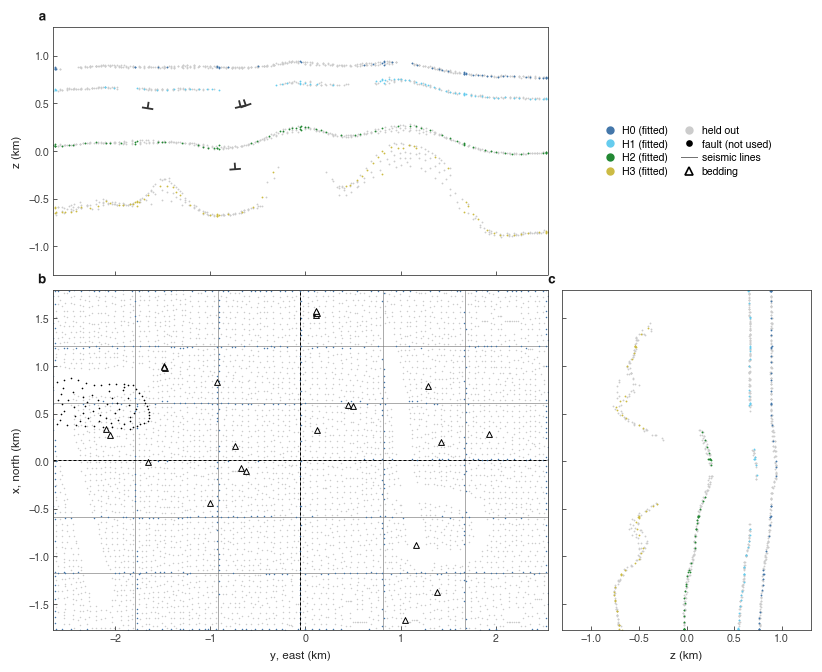

In [5]:
# The data for the supplement: a plan view, with a section along y above it and one along x
# beside it, sharing their axes. The sections show the points within SLAB of the centre lines;
# the plan shows H0 alone, with the seismic lines, so the sampling can be seen. Points kept for
# fitting (the picks along the lines, as the fits keep them) in the horizon colours, held-out points in grey;
# the fault in black; bedding as way-up T-bars (sections) and triangles (plan). Each section is taken along
# the seismic line nearest the centre of the survey, so it shows the fitted picks along that line.
import claudius_inputs
from matplotlib.lines import Line2D

LINES = claudius_inputs.SEISMIC_LINES        # the sampling the fits use
SLAB = 150.0                                   # m, half-width of the slab each section shows
LABELS = [f"H{k}" for k in range(len(HORIZONS))]   # A (youngest) .. D, as in the paper
line_x, line_y = claudius_inputs.seismic_lines(claudius_inputs.pick_extent(points), LINES["n_x"], LINES["n_y"],
                                               LINES.get("bounds", True))
kept = [claudius_inputs.seismic_keep(p, line_x, line_y, LINES["half_width"]) for p in points]
SX = float(line_x[np.argmin(np.abs(line_x))])  # section a: along the line of constant x nearest the centre
SY = float(line_y[np.argmin(np.abs(line_y))])  # section c: along the line of constant y nearest the centre
print(f"kept {sum(k.sum() for k in kept)} of {sum(len(p) for p in points)} picks; sections at x = {SX:.0f} m, y = {SY:.0f} m")

KM = 1e-3
W = figstyle.PRINT_WIDTH
left, right, bottom, top, gap = 0.62, 0.15, 0.5, 0.15, 0.12
s = (W - left - right - gap) / (np.ptp(box[:, 1]) + np.ptp(box[:, 2])) # inches per m
w_plan, h_plan, d_z = np.ptp(box[:, 1]) * s, np.ptp(box[:, 0]) * s, np.ptp(box[:, 2]) * s
H = bottom + h_plan + gap + d_z + top
fig = figstyle.print_figure(height=H)
place = lambda x0, y0, w, h: fig.add_axes((x0 / W, y0 / H, w / W, h / H))
ax_plan = place(left, bottom, w_plan, h_plan)                       # y (east) across, x (north) up
ax_ey = place(left, bottom + h_plan + gap, w_plan, d_z)             # y across, z up
ax_nx = place(left + w_plan + gap, bottom, d_z, h_plan)             # z across, x up


def scatter(ax, i, j, slab_axis=None, which=None, s=0.6):
    centre = {0: SX, 1: SY}.get(slab_axis, 0.0)
    near = (lambda p: np.abs(p[:, slab_axis] - centre) <= SLAB) if slab_axis is not None else (lambda p: np.ones(len(p), bool))
    sets = [h for h in range(len(points)) if which is None or h in which]
    for h in sets:
        p, m = points[h], near(points[h])
        ax.scatter(p[m & ~kept[h], i] * KM, p[m & ~kept[h], j] * KM, s=s, color="0.8", linewidths=0, rasterized=True, zorder=1)
    for h in sets:
        p, m = points[h], near(points[h])
        ax.scatter(p[m & kept[h], i] * KM, p[m & kept[h], j] * KM, s=s, color=figstyle.HORIZON_PALETTE[h],
                   linewidths=0, rasterized=True, zorder=2)
    mf = near(fault)
    ax.scatter(fault[mf, i] * KM, fault[mf, j] * KM, s=1.0, color="k", linewidths=0, rasterized=True, zorder=3)


scatter(ax_plan, 1, 0, which=(0,), s=0.8)
ax_plan.scatter(gp[:, 1] * KM, gp[:, 0] * KM, s=12, marker="^", color="w", edgecolors="k", linewidths=0.6, zorder=4)
for a in line_x:                                                     # the seismic lines
    ax_plan.axhline(a * KM, color="0.45", lw=0.35, zorder=0)
for b in line_y:
    ax_plan.axvline(b * KM, color="0.45", lw=0.35, zorder=0)
ax_plan.axhline(SX * KM, color="k", lw=0.6, ls=(0, (3, 2)))           # trace of section a
ax_plan.axvline(SY * KM, color="k", lw=0.6, ls=(0, (3, 2)))           # trace of section c
scatter(ax_ey, 1, 2, slab_axis=0, s=1.2)
near_x = np.abs(gp[:, 0] - SX) <= SLAB
figstyle.draw_younging(ax_ey, gp[near_x][:, (1, 2)] * KM, gv[near_x][:, (1, 2)], quiver_scale=7.0)   # T-bars about 0.13 km
scatter(ax_nx, 2, 0, slab_axis=1, s=1.2)
near_y = np.abs(gp[:, 1] - SY) <= SLAB
figstyle.draw_younging(ax_nx, gp[near_y][:, (2, 0)] * KM, gv[near_y][:, (2, 0)], quiver_scale=7.0)
for ax, (h, v) in ((ax_plan, (1, 0)), (ax_ey, (1, 2)), (ax_nx, (2, 0))):
    ax.set_xlim(*(box[:, h] * KM))
    ax.set_ylim(*(box[:, v] * KM))
    ax.set_aspect("equal")
ax_plan.set_xlabel("y, east (km)")
ax_plan.set_ylabel("x, north (km)")
ax_ey.set_ylabel("z (km)")
ax_ey.tick_params(labelbottom=False)
ax_nx.set_xlabel("z (km)")
ax_nx.tick_params(labelleft=False)
for ax, letter in ((ax_ey, "a"), (ax_plan, "b"), (ax_nx, "c")):
    figstyle.panel_label(ax, letter)

handles = [Line2D([], [], ls="", marker="o", ms=4, color=colr, label=f"{n} (fitted)")
           for n, colr in zip(LABELS, figstyle.HORIZON_PALETTE)]
handles += [Line2D([], [], ls="", marker="o", ms=4, color="0.8", label="held out"),
            Line2D([], [], ls="", marker="o", ms=3, color="k", label="fault (not used)"),
            Line2D([], [], color="0.45", lw=0.6, label="seismic lines"),
            Line2D([], [], ls="", marker="^", ms=5, mfc="w", mec="k", label="bedding")]
fig.legend(handles=handles, loc="center", ncol=2, frameon=False,     # the empty corner beside section a
           bbox_to_anchor=((left + w_plan + gap + 0.5 * d_z) / W, (bottom + h_plan + gap + 0.5 * d_z) / H))
FIG_DIR = Path("./figures/supplement")
FIG_DIR.mkdir(parents=True, exist_ok=True)
written = figstyle.save(fig, FIG_DIR / "figS_claudius_data")
print("wrote", *written, sep="\n  ")
plt.show()


## Seismic-line sampling (alternative to the evenly spaced fraction)

`claudius_inputs.load_processed(sampling="seismic")` keeps only the contacts along hypothetical 2-D seismic
lines: lines of constant x (running east-west) and of constant y (north-south), evenly spaced across the
extent of the picks, with the two bounding lines of each direction at that extent so the outermost picks are kept;
the contacts within `half_width` of a line are kept. Everything between the lines is held out, so the held-out score is how well a fit
interpolates across the gaps, hundreds of metres, not between neighbouring picks 40 m apart. The bedding is
kept whole. This cell only looks at the design on a plan view of H0 (not saved); the fits (`06b`, `06c`) choose it
with `SAMPLING = "seismic"` and `LINES`.

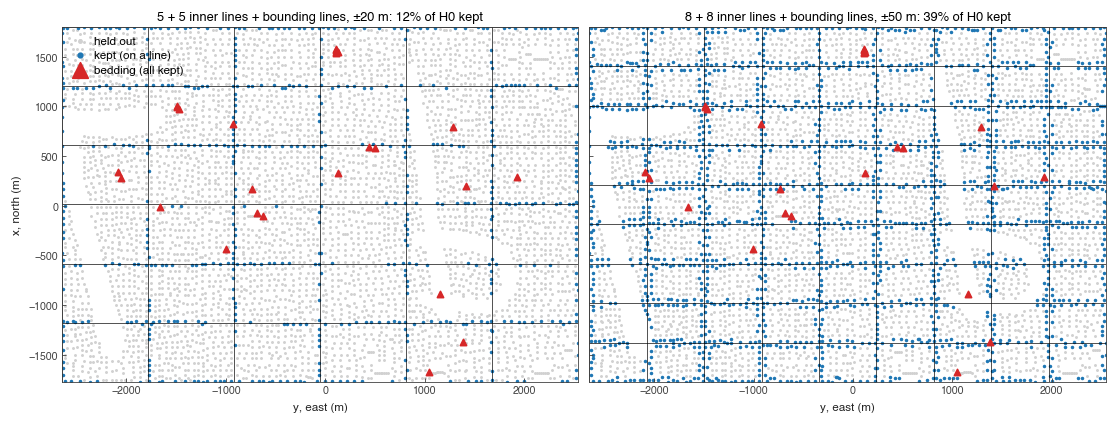

In [6]:
import claudius_inputs

DESIGNS = [claudius_inputs.SEISMIC_LINES, dict(n_x=8, n_y=8, half_width=50.0, bounds=True)]
extent = claudius_inputs.pick_extent(points)   # the survey's outline: the bounding lines sit on it
fig_sl, axs_sl = plt.subplots(1, len(DESIGNS), figsize=(4.6 * len(DESIGNS), 6), sharey=True, constrained_layout=True)
for ax_sl, lines_sl in zip(np.atleast_1d(axs_sl), DESIGNS):
    lx, ly = claudius_inputs.seismic_lines(extent, lines_sl["n_x"], lines_sl["n_y"], lines_sl.get("bounds", True))
    keep_sl = claudius_inputs.seismic_keep(points[0], lx, ly, lines_sl["half_width"])
    ax_sl.scatter(points[0][~keep_sl, 1], points[0][~keep_sl, 0], s=0.6, color="0.82", label="held out")
    ax_sl.scatter(points[0][keep_sl, 1], points[0][keep_sl, 0], s=1.2, color="C0", label="kept (on a line)")
    for a in lx:
        ax_sl.axhline(a, color="k", lw=0.4)
    for b in ly:
        ax_sl.axvline(b, color="k", lw=0.4)
    ax_sl.scatter(gp[:, 1], gp[:, 0], marker="^", s=14, color="C3", label="bedding (all kept)", zorder=3)
    ax_sl.set(aspect="equal", xlim=(box[0, 1], box[1, 1]), ylim=(box[0, 0], box[1, 0]), xlabel="y, east (m)",
              title=f"{lines_sl['n_x']} + {lines_sl['n_y']} inner lines + bounding lines, ±{lines_sl['half_width']:g} m: "
                    f"{keep_sl.mean():.0%} of H0 kept")
np.atleast_1d(axs_sl)[0].set_ylabel("x, north (m)")
np.atleast_1d(axs_sl)[0].legend(loc="upper left", fontsize=7, frameon=False, markerscale=2.5)
plt.show()

## Save

In [7]:
np.savez_compressed(
    OUT_DIR / "claudius_processed.npz",
    origin=origin, horizon_names=np.array(HORIZONS), gp=gp, gv=gv, fault=fault,
    x=x, y=y, z=z, box=box,
    **{f"horizon_{h}": p for h, p in enumerate(points)},
    **{f"cutoff_{h}": c for h, c in enumerate(cutoffs)},
)
(OUT_DIR / "settings.json").write_text(json.dumps(
    {"box_utm": (box + origin).tolist(), "benchmark_box_utm": BOX_UTM.tolist(), "clamped_to_picks": bool(CLAMP_TO_PICKS), "step_m": STEP.tolist(), "horizons": list(HORIZONS),
     "frame": "UTM minus the box centre; z = -3 x two-way time, up",
     "bedding": "Dips.csv poles negated (younging up)", "fault": "saved, not used by the fits"}, indent=1))
print("wrote", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

wrote
  claudius_processed.npz
  settings.json
